# GENIE BPC BLADDER v1.0-public — questions B1–B2

Source: Jacob's *CBIO thoughts* deck, slide 14. Data: AACR Project GENIE BPC BLADDER v1.0-public (Synapse).

Conventions as in `README.md`: index date = diagnosis of the index bladder cancer, OS in months; treatment questions use OS from regimen start in
the metastatic setting. **CDKN2A/B altered** = deep deletion or non-synonymous mutation of CDKN2A or CDKN2B (deep deletion is the usual mechanism).
Patients compared for a gene only if their panel covers it; KM / log-rank as cBioPortal, Cox HR left-truncated at the sequencing report (*HR (LT)*).

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_bladder"
F = []

b = cb.BPC("BLADDER")
pd.Series(b.summary())

cohort                            BLADDER
patients                              716
index_cancers                         716
patients_with_2+_index_cancers          0
samples                               744
samples_used                          716
regimens                             1831
mutations_nonsyn                    11013
cna_profiled_samples                  673
sv_rows                               289
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "BLADDER"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['1.0-public']


,category,filename,synapse_id,version,md5
118,docs,GENIE BPC BLADDER v1.0-public Analytic Data Gu...,syn74221362,2,36a69c16c0aab255e17d9ec4d49cb3f9
119,docs,GENIE BPC BLADDER v1.0-public Variable Synopsi...,syn74221361,2,f4ea8d6fe6ee137ac795fae9619d425e
120,docs,GENIE BPC BLADDER v1.0-public Release Notes.pdf,syn74221360,1,62bb1c704b4c48bac699151809c7d0b3
121,analytic,patient_level_dataset.csv,syn75201456,1,3494762b9429f8a20735add8db6bd414
122,analytic,cancer_level_dataset_index.csv,syn75201447,1,5d21475f30f2bba0fe0bb3c4c7f1c534
123,analytic,cancer_level_dataset_non_index.csv,syn75201450,1,53b34ddff4714b97163bbd822afb47b7
124,analytic,cancer_panel_test_level_dataset.csv,syn75201451,1,0b50f3ce9b749b4e8a36d7f4524a1a2f
125,analytic,regimen_cancer_level_dataset.csv,syn75201457,1,38152644a5bb1d82c34ca21cd3a26228
126,analytic,imaging_level_dataset.csv,syn75201452,1,ea41d75aa81baf891de5f1b16340e0dc
127,analytic,med_onc_note_level_dataset.csv,syn75201453,1,f07acc300ad25c8b064159da653f9206


## Cohort and alteration matrix
The deck asks about *bladder urothelial carcinoma*; the histology / OncoTree code of the sequenced sample is used to restrict to urothelial tumours.

oncotree
BLCA    566
UTUC    110
BLAD     20
SCBC     11
BLSC      9
Name: OncoTree code of sample used, dtype: int64

,step,n,dropped
0,Patients in release,716,0
1,Index bladder cancer (first index cancer per p...,716,0
2,With a sequenced sample of the index cancer,716,0
3,Urothelial carcinoma (OncoTree / histology),706,10


0 patients had two index cancers (first used); 0 samples with unknown panel. Deaths: 389 / 706; median OS from dx: 56.9 months.


stage_dx
Stage IV           236
Stage I            179
Stage II           156
Stage III          121
Stage 0              6
Stage I-III NOS      5
Name: stage_dx, dtype: int64

,gene,kind,n_altered,n_tested,pct
0,TP53,mut,383,706,54.2
1,KMT2D,mut,229,683,33.5
2,KDM6A,mut,186,683,27.2
3,ARID1A,mut,178,688,25.9
4,PIK3CA,mut,147,706,20.8
5,CDKN2A,homdel,146,634,23
6,CDKN2B,homdel,141,634,22.2
7,RB1,mut,116,705,16.5
8,FGFR3,mut,113,706,16
9,CREBBP,mut,101,688,14.7


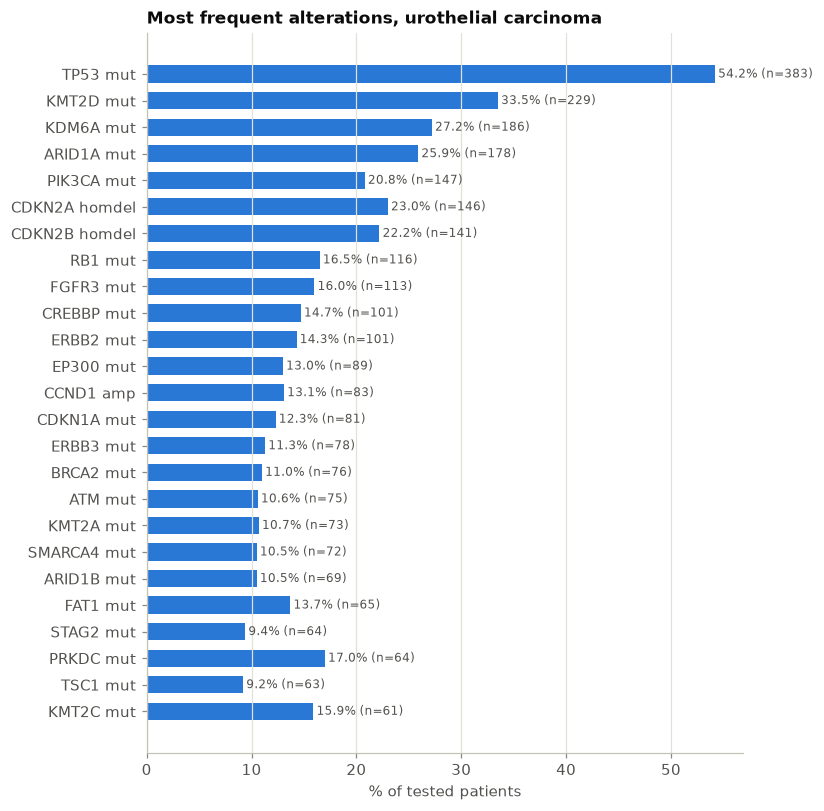

In [3]:
S = b.survival_dx()
A = b.alterations()
onc = S.index.to_series().map(b.samples.cpt_oncotree_code)
S["oncotree"] = onc
display(S.oncotree.value_counts().head(10).rename("OncoTree code of sample used"))
uro_codes = {"BLCA", "UTUC", "UCU", "BLSC", "URCC", "UCA", "UPA", "BLAD"}      # urothelial carcinoma OncoTree codes (bladder and upper tract)
hist_code = pd.to_numeric(S.get("naaccr_histology_cd", pd.Series(index=S.index, dtype=float)), errors="coerce")
hist_text = S.get("ca_histology", pd.Series(index=S.index, dtype=object)).astype(str)
S["urothelial"] = S.oncotree.isin(uro_codes) | hist_code.between(8120, 8131) | hist_text.str.contains("rothelial|ransitional", na=False)   # ICD-O-3 8120–8131 = urothelial / transitional cell
if S.urothelial.sum() == 0:
    raise RuntimeError(f"no urothelial patients found; OncoTree codes present: {S.oncotree.value_counts().head(10).to_dict()}")
display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index bladder cancer (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("Urothelial carcinoma (OncoTree / histology)", int(S.urothelial.sum())),
]))
U = S[S.urothelial].copy()
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel. Deaths: {int(U.event.sum())} / {len(U)}; "
      f"median OS from dx: {cb.km_table(U.assign(g='all'), 'g').median_months[0]} months.")
display(U.stage_dx.value_counts().rename("stage_dx"))
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"), patients=U.index)
ax = cb.bar_freq(freq, top=25, title="Most frequent alterations, urothelial carcinoma")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
freq.head(15)

## B1 — How do bladder urothelial carcinoma patients do with CDKN2A or CDKN2B alterations?

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,CDKN2A/B intact,518,263,70.3,0.939,0.792,0.542,5.93e-05,NaN,NaN,NaN,NaN
1,CDKN2A/B altered,187,125,36.2,0.864,0.609,0.361,5.93e-05,1.75,1.41,2.18,4.86e-07


n  events  median_months  surv_1y  surv_2y  surv_5y  p_logrank   HR  HR_lo  HR_hi    p_cox
feature       group                                                                                                
CDKN2A homdel absent   488     236           74.4    0.944    0.788    0.557   4.37e-07  NaN    NaN    NaN      NaN
              present  146     102           35.5    0.845    0.576     0.33   4.37e-07 1.99   1.57   2.52 9.89e-09
CDKN2B homdel absent   493     240           74.4     0.94    0.782    0.554   1.71e-06  NaN    NaN    NaN      NaN
              present  141      98           35.8    0.854     0.59    0.332   1.71e-06 1.96   1.54   2.49 3.34e-08
CDKN2A mut    absent   665     364           58.3    0.918    0.745    0.496      0.961  NaN    NaN    NaN      NaN
              present   40      24           49.8    0.925    0.716    0.451      0.961 1.18  0.778   1.79    0.434
MTAP homdel   absent   614     323           62.6    0.927    0.746    0.513    0.00444  NaN    NaN    NaN      NaN
              present   20      15           33.7     0.75     0.55      0.3    0.00444 1.72      1   2.95   0.0482

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,CDKN2A/B intact,171,108,37.2,0.85,0.631,0.376,0.000269,NaN,NaN,NaN,NaN
1,CDKN2A/B altered,65,54,18.9,0.719,0.345,0.176,0.000269,1.77,1.27,2.47,0.000753


[B1] signal: Urothelial n=705: CDKN2A/B altered n=187 median OS 36.2 vs 70.3 mo, log-rank p=5.9e-05, HR (LT, stage/age-adjusted) 1.75 [1.41-2.18]; stage IV only HR 1.77 (p=7.5e-04).


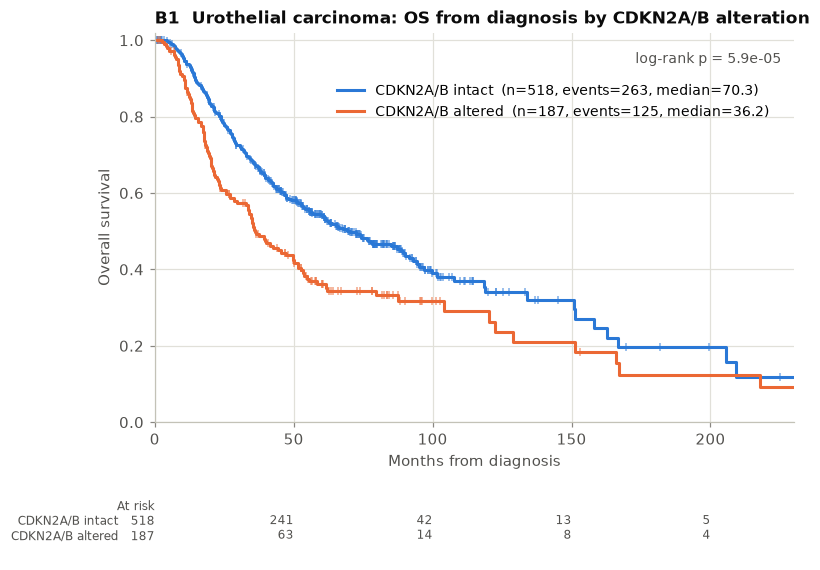

In [4]:
cdk = (A.status("CDKN2A", "homdel") | A.status("CDKN2A", "mut") | A.status("CDKN2B", "homdel") | A.status("CDKN2B", "mut")).rename("cdkn2ab")
d, t1 = cb.compare(U, cdk, labels=("CDKN2A/B intact", "CDKN2A/B altered"), entry="entry", adjust=["stage_dx", "age_dx"])
ax, _ = cb.km_plot(d, "group", order=["CDKN2A/B intact", "CDKN2A/B altered"], title="B1  Urothelial carcinoma: OS from diagnosis by CDKN2A/B alteration", xlabel="Months from diagnosis")
cb.save(DS, "B1", table=t1, fig=ax.figure, slug="cdkn2ab_vs_intact")
display(t1)
rows = []
for g, k in [("CDKN2A", "homdel"), ("CDKN2B", "homdel"), ("CDKN2A", "mut"), ("MTAP", "homdel")]:
    _, t = cb.compare(U, A.status(g, k), labels=("absent", "present"), entry="entry")
    rows.append(t.assign(feature=f"{g} {k}"))
parts = pd.concat(rows).set_index(["feature", "group"])
cb.save(DS, "B1", table=parts.reset_index(), slug="components")
display(parts)
# stage IV only
d4, t1b = cb.compare(U[U.stage_dx == "Stage IV"], cdk, labels=("CDKN2A/B intact", "CDKN2A/B altered"), entry="entry", adjust=["age_dx"])
display(t1b)
cb.finding("B1", "signal" if t1.attrs["p_cox"] < 0.05 else "no signal",
           f"Urothelial n={len(d)}: CDKN2A/B altered n={t1.n[1]} median OS {t1.median_months[1]} vs {t1.median_months[0]} mo, log-rank p={cb.fmt_p(t1.p_logrank[0])}, "
           f"HR (LT, stage/age-adjusted) {t1.attrs['HR']:.2f} [{t1.attrs['HR_lo']:.2f}-{t1.attrs['HR_hi']:.2f}]; stage IV only HR {t1b.attrs['HR']:.2f} (p={cb.fmt_p(t1b.attrs['p_cox'])}).", F)

## B2 — How is OS affected by different treatments, especially in the CDKN2A/B group?
First regimen of each class per patient (metastatic setting), OS from regimen start; within each class, CDKN2A/B altered vs intact.

,treatment,n,events,median_months,first_line_pct,n_altered,median_altered,median_intact,p_logrank,HR_LT,HR_lo,HR_hi
0,platinum chemotherapy,310,225,24.5,78.4,91,17.4,27.3,4.28e-05,1.73,1.31,2.29
1,cisplatin-based,211,143,29.7,83.4,55,18.5,35.6,0.000744,1.68,1.18,2.41
2,carboplatin-based,152,123,14.7,44.1,49,10.6,17.5,0.13,1.52,1.04,2.21
3,immunotherapy,210,153,14.2,11.4,72,9.7,17,0.0176,1.47,1.06,2.05
4,enfortumab vedotin,15,5,16.8,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,taxane,147,121,10.9,17.7,40,11,10.9,0.859,0.906,0.603,1.36
6,gemcitabine-containing,300,215,22.7,72,87,16.4,26,0.000222,1.59,1.19,2.13


[B2] descriptive: Median OS from regimen start (urothelial, metastatic setting): platinum chemotherapy 24.5 mo (n=310), cisplatin-based 29.7 mo (n=211), carboplatin-based 14.7 mo (n=152), immunotherapy 14.2 mo (n=210), enfortumab vedotin 16.8 mo (n=15), taxane 10.9 mo (n=147), gemcitabine-containing 22.7 mo (n=300). CDKN2A/B altered vs intact within class: platinum chemotherapy HR 1.73 (p=4.3e-05), cisplatin-based HR 1.68 (p=7.4e-04), carboplatin-based HR 1.52 (p=0.130), immunotherapy HR 1.47 (p=0.018), taxane HR 0.91 (p=0.859), gemcitabine-containing HR 1.59 (p=2.2e-04).


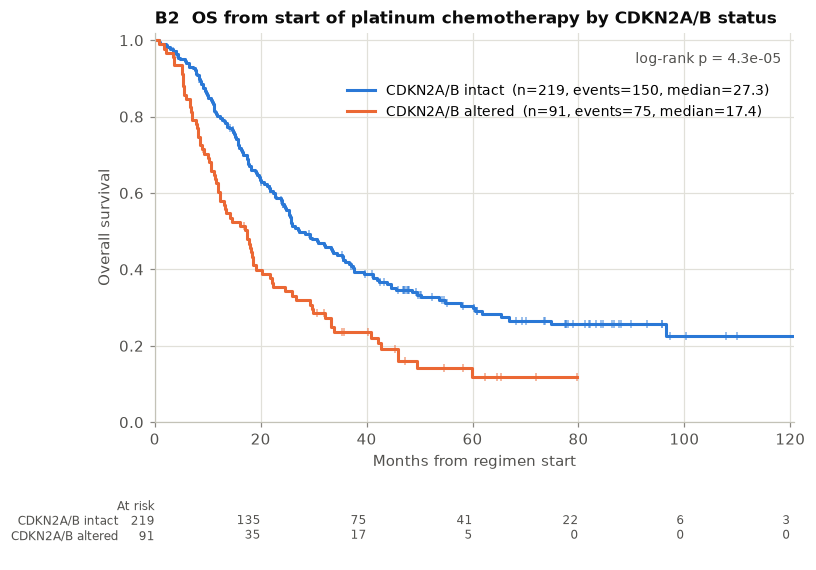

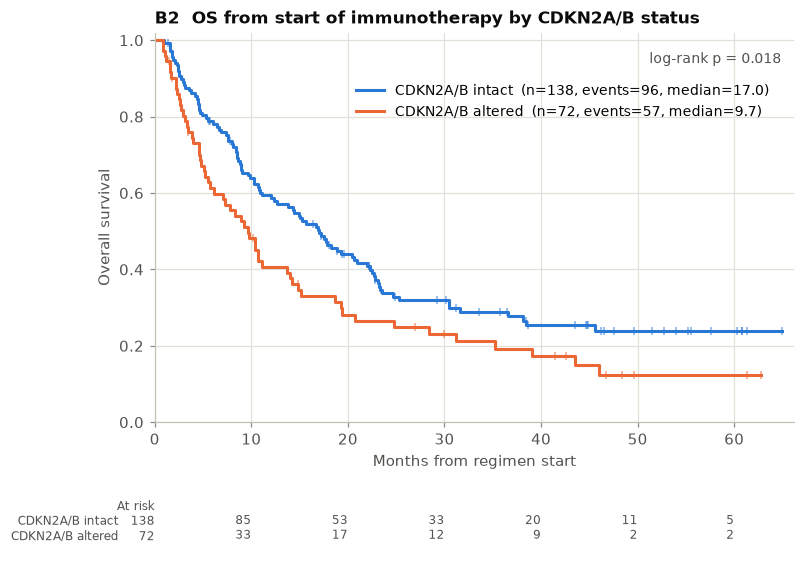

In [5]:
CLASSES = {
    "platinum chemotherapy": dict(pattern="Cisplatin|Carboplatin"),
    "cisplatin-based": dict(pattern="Cisplatin"),
    "carboplatin-based": dict(pattern="Carboplatin", exclude="Cisplatin"),
    "immunotherapy": dict(pattern="|".join(cb.IO)),
    "enfortumab vedotin": dict(pattern="Enfortumab"),
    "FGFR inhibitor": dict(pattern="Erdafitinib|Infigratinib|Pemigatinib"),
    "taxane": dict(pattern="Paclitaxel|Docetaxel|Nabpaclitaxel"),
    "gemcitabine-containing": dict(pattern="Gemcitabine"),
}
rows, kms = [], {}
for name, kw in CLASSES.items():
    R = b.survival_regimen(**kw)
    R = R[R.met_setting & R.index.isin(U.index)].join(cdk.rename("feat"), how="inner")
    if len(R) < 10:
        continue
    t = cb.km_table(R.assign(g=name), "g")
    row = dict(treatment=name, n=t.n[0], events=t.events[0], median_months=t.median_months[0], first_line_pct=round(100 * (R.line == 1).mean(), 1))
    n_alt, n_wt = int(R.feat.sum()), int((~R.feat).sum())
    if n_alt >= 10 and n_wt >= 10:
        R["group"] = np.where(R.feat, "CDKN2A/B altered", "CDKN2A/B intact")
        tt = cb.km_table(R, "group", order=["CDKN2A/B intact", "CDKN2A/B altered"])
        h = cb.hr(R, "feat", entry="entry")
        row.update(n_altered=n_alt, median_altered=tt.median_months[1], median_intact=tt.median_months[0], p_logrank=tt.p_logrank[0], HR_LT=h["HR"], HR_lo=h["HR_lo"], HR_hi=h["HR_hi"])
        kms[name] = R
    rows.append(row)
b2 = pd.DataFrame(rows)
cb.save(DS, "B2", table=b2, slug="os_by_treatment_class_and_cdkn2ab")
display(b2)
for name in [n for n in ["platinum chemotherapy", "immunotherapy", "enfortumab vedotin"] if n in kms]:
    ax, t = cb.km_plot(kms[name], "group", order=["CDKN2A/B intact", "CDKN2A/B altered"], title=f"B2  OS from start of {name} by CDKN2A/B status", xlabel="Months from regimen start")
    cb.save(DS, "B2", table=t, fig=ax.figure, slug="km_" + re.sub(r"[^a-z]+", "_", name))
sig = b2.dropna(subset=["p_logrank"]) if "p_logrank" in b2 else b2.iloc[0:0]
sig = sig[sig.p_logrank < 0.05]
cb.finding("B2", "descriptive",
           "Median OS from regimen start (urothelial, metastatic setting): " + ", ".join(f"{r.treatment} {r.median_months} mo (n={r.n})" for r in b2.itertuples()) +
           ". CDKN2A/B altered vs intact within class: " + (", ".join(f"{r.treatment} HR {r.HR_LT:.2f} (p={cb.fmt_p(r.p_logrank)})" for r in b2.dropna(subset=['HR_LT']).itertuples()) or "no class with >=10 per group") + ".", F)

## Summary of findings

In [6]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,B1,signal,"Urothelial n=705: CDKN2A/B altered n=187 median OS 36.2 vs 70.3 mo, log-rank p=5.9e-05, HR (LT, stage/age-adjusted) 1.75 [1.41-2.18]; stage IV only HR 1.77 (p=7.5e-04)."
1,B2,descriptive,"Median OS from regimen start (urothelial, metastatic setting): platinum chemotherapy 24.5 mo (n=310), cisplatin-based 29.7 mo (n=211), carboplatin-based 14.7 mo (n=152), immunotherapy 14.2 mo (n=210), enfortumab vedotin 16.8 mo (n=15), taxane 10.9 mo (n=147), gemcitabine-containing 22.7 mo (n=300). CDKN2A/B altered vs intact within class: platinum chemotherapy HR 1.73 (p=4.3e-05), cisplatin-ba..."
